<a href="https://colab.research.google.com/github/DNL139/pi_tec_BD_supermercado/blob/main/pi_tec_BD_supermercado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto Integrador - Análise de Dados de Supermercado

**Instituição:** SENAC EAD  
**Curso:** Tecnologia em Banco de Dados  
**Disciplina:** PI: Ciência de Dados Aplicada a Situações de Mercado  
**Fonte dos dados:** [Supermarket Sales Dataset - Kaggle](https://www.kaggle.com/datasets/faresashraf1001/supermarket-sales/data)  
**Período analisado:** 1º de janeiro a 30 de março de 2019


## 1. Introdução

Este projeto tem como objetivo desenvolver uma prova de conceito de Ciência de Dados e Inteligência de Negócios (Business Intelligence – BI), utilizando técnicas de análise exploratória, visualização de dados, modelagem de banco de dados e aprendizado de máquina para apoiar a tomada de decisão no setor supermercadista.

Para isso, foi utilizada uma base pública de dados contendo 1.000 transações comerciais de uma rede de supermercados, realizadas entre janeiro e março de 2019. O conjunto de dados apresenta informações sobre filiais, categorias de produtos, tipos de clientes, formas de pagamento, quantidades vendidas, valores das transações (em dólares americanos) e avaliações de satisfação.

Inicialmente, os dados são carregados e tratados utilizando Python, com apoio das bibliotecas Pandas e NumPy. Em seguida, são realizadas análises exploratórias e visualizações com Matplotlib, visando identificar padrões de faturamento, comportamento das vendas e diferenças de desempenho entre filiais e categorias.

Na segunda etapa, o projeto incorpora a aplicação do algoritmo K-Means, por meio da biblioteca Scikit-learn, para agrupar transações com características semelhantes quanto à quantidade de produtos e ao valor das compras. Os resultados são apresentados em um dashboard interativo desenvolvido com Streamlit e Plotly, permitindo a exploração de indicadores comerciais e a aplicação de filtros por período, filial, categoria de produto e forma de pagamento.

Complementarmente, foi desenvolvida uma estrutura dimensional no MySQL, organizada segundo o modelo *Star Schema*, com tabelas relacionadas, mecanismos de integridade e consultas analíticas destinadas ao apoio à decisão. Essa implementação constitui um componente complementar ao processamento realizado no notebook, contribuindo para demonstrar os recursos de armazenamento, administração e análise de dados estudados ao longo do curso.

**Objetivos específicos:**

- Realizar o carregamento, o tratamento e a análise exploratória dos dados.
- Desenvolver visualizações que auxiliem na interpretação dos indicadores comerciais.
- Aplicar o algoritmo K-Means para identificar diferentes perfis de transações.
- Demonstrar recursos de modelagem, administração e análise de dados utilizando MySQL.
- Disponibilizar os resultados em uma interface visual e interativa.
- Interpretar os resultados sob a perspectiva gerencial, identificando possibilidades de melhoria e limitações das análises realizadas.

In [1]:
# Importação de bibliotecas e Paleta de Cores
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from PIL import Image
from urllib.request import urlretrieve

# Mapeamento da Paleta de Cores do Senac
AZUL_SENAC = '#004a8d'
LARANJA_SENAC = '#f7941e'
LARANJA_CLARO = '#fdc17f'

# Carregamento automático da logo a partir do GitHub
url_logo = (
    "https://raw.githubusercontent.com/"
    "DNL139/pi_tec_BD_supermercado/main/logo_senac.png"
)

caminho_logo = "logo_senac.png"

try:
    urlretrieve(url_logo, caminho_logo)
    print("Logo carregada com sucesso!")
except Exception as erro:
    print(f"Não foi possível carregar a logo: {erro}")

Logo carregada com sucesso!


In [2]:
# Carregamento da base
caminho_arquivo = (
    "https://raw.githubusercontent.com/"
    "DNL139/pi_tec_BD_supermercado/main/"
    "dataset/SuperMarket%20Analysis.csv"
)

df = pd.read_csv(caminho_arquivo)

print("Base carregada com sucesso!")
print(f"Quantidade de registros: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")

Base carregada com sucesso!
Quantidade de registros: 1000
Quantidade de colunas: 17


In [3]:
# Visualizar primeiras linhas
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [4]:
# Informações gerais do dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Sales                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

## 2. Limpeza e tratamento dos dados

Nesta etapa vamos:
- Converter colunas de data e hora para tipos adequados
- Verificar valores nulos
- Criar colunas derivadas úteis para análise (ex.: dia da semana, horário)

In [5]:
# Conversão de tipos


# Converter coluna Date para datetime
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')

# Converter coluna Time para datetime (apenas hora)
df['Time'] = pd.to_datetime(df['Time']).dt.time

# Conferir novamente
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Invoice ID               1000 non-null   object        
 1   Branch                   1000 non-null   object        
 2   City                     1000 non-null   object        
 3   Customer type            1000 non-null   object        
 4   Gender                   1000 non-null   object        
 5   Product line             1000 non-null   object        
 6   Unit price               1000 non-null   float64       
 7   Quantity                 1000 non-null   int64         
 8   Tax 5%                   1000 non-null   float64       
 9   Sales                    1000 non-null   float64       
 10  Date                     1000 non-null   datetime64[ns]
 11  Time                     1000 non-null   object        
 12  Payment                  1000 non-n

C:\Users\lucas\AppData\Local\Temp\ipykernel_27548\492906372.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Time'] = pd.to_datetime(df['Time']).dt.time


In [6]:
# Verificação de nulos e duplicatas


# Verificar valores nulos
print("Valores nulos por coluna:")
print(df.isnull().sum())

# Verificar duplicatas
print("\nRegistros duplicados:", df.duplicated().sum())

# Remover duplicatas, se houver
df = df.drop_duplicates()

Valores nulos por coluna:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Sales                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Registros duplicados: 0


In [7]:
#  Verificação da consistência financeira com NumPy


valores_esperados = df['cogs'] + df['Tax 5%']

vendas_consistentes = np.isclose(
    df['Sales'],
    valores_esperados
)

print(
    "Registros financeiramente consistentes:",
    np.sum(vendas_consistentes)
)

print(
    "Registros financeiramente inconsistentes:",
    np.sum(~vendas_consistentes)
)

Registros financeiramente consistentes: 1000
Registros financeiramente inconsistentes: 0


In [8]:
# Criação de colunas derivadas


# Criar coluna de dia da semana
df['DayOfWeek'] = df['Date'].dt.day_name()

# Criar coluna de hora (inteiro)
df['Hour'] = pd.to_datetime(df['Time'], format='%H:%M:%S').dt.hour

# Criar coluna de período do dia (manhã/tarde/noite)
def periodo_do_dia(hora):
    if hora < 12:
        return 'Manhã'
    elif hora < 18:
        return 'Tarde'
    else:
        return 'Noite'

df['Period'] = df['Hour'].apply(periodo_do_dia)

df[['Date', 'Time', 'DayOfWeek', 'Hour', 'Period']].head()

,Date,Time,DayOfWeek,Hour,Period
0,2019-01-05,13:08:00,Saturday,13,Tarde
1,2019-03-08,10:29:00,Friday,10,Manhã
2,2019-03-03,13:23:00,Sunday,13,Tarde
3,2019-01-27,20:33:00,Sunday,20,Noite
4,2019-02-08,10:37:00,Friday,10,Manhã


## 3. Análise Exploratória de Dados (EDA)

Nesta etapa, exploramos os principais aspectos da base de dados utilizados nas análises e visualizações do projeto. O foco está no faturamento por categoria e filial, na quantidade de transações por horário, nas formas de pagamento e na avaliação média dos clientes por categoria de produto.

In [9]:
# Visão geral da base


df.head()
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Invoice ID               1000 non-null   object        
 1   Branch                   1000 non-null   object        
 2   City                     1000 non-null   object        
 3   Customer type            1000 non-null   object        
 4   Gender                   1000 non-null   object        
 5   Product line             1000 non-null   object        
 6   Unit price               1000 non-null   float64       
 7   Quantity                 1000 non-null   int64         
 8   Tax 5%                   1000 non-null   float64       
 9   Sales                    1000 non-null   float64       
 10  Date                     1000 non-null   datetime64[ns]
 11  Time                     1000 non-null   object        
 12  Payment                  1000 non-n

,Unit price,Quantity,Tax 5%,Sales,Date,cogs,gross margin percentage,gross income,Rating,Hour
count,1000.000000,1000.000000,1000.000000,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.00000,1000.000000
mean,55.672130,5.510000,15.379369,322.966749,2019-02-14 00:05:45.600000,307.58738,4.761905,15.379369,6.97270,14.910000
min,10.080000,1.000000,0.508500,10.678500,2019-01-01 00:00:00,10.17000,4.761905,0.508500,4.00000,10.000000
25%,32.875000,3.000000,5.924875,124.422375,2019-01-24 00:00:00,118.49750,4.761905,5.924875,5.50000,12.000000
50%,55.230000,5.000000,12.088000,253.848000,2019-02-13 00:00:00,241.76000,4.761905,12.088000,7.00000,15.000000
75%,77.935000,8.000000,22.445250,471.350250,2019-03-08 00:00:00,448.90500,4.761905,22.445250,8.50000,18.000000
max,99.960000,10.000000,49.650000,1042.650000,2019-03-30 00:00:00,993.00000,4.761905,49.650000,10.00000,20.000000
std,26.494628,2.923431,11.708825,245.885335,NaN,234.17651,0.000000,11.708825,1.71858,3.186857


In [10]:
# Faturamento por categoria de produto

df.groupby('Product line')['Sales'].sum().sort_values(ascending=False)

Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Sales, dtype: float64

In [11]:
# Faturamento por filial

df.groupby('Branch')['Sales'].sum()

Branch
Alex     106200.3705
Cairo    106197.6720
Giza     110568.7065
Name: Sales, dtype: float64

In [12]:
# Categorias mais vendidas por filial

cat_por_filial = df.groupby(['Branch', 'Product line']).agg({'Quantity':'sum'})
grupos = cat_por_filial['Quantity'].groupby('Branch',group_keys=False)
max_por_filial = grupos.apply(lambda grupo: grupo.sort_values(ascending=False).head(1))
max_por_filial

Branch  Product line      
Alex    Home and lifestyle    371
Cairo   Sports and travel     322
Giza    Food and beverages    369
Name: Quantity, dtype: int64

In [13]:
# Quantidade de transações por horário

transacoes_horario = (
    df.groupby('Hour')['Invoice ID']
      .count()
      .sort_index()
)

transacoes_horario

Hour
10    101
11     90
12     89
13    103
14     83
15    102
16     77
17     74
18     93
19    113
20     75
Name: Invoice ID, dtype: int64

In [14]:
# Formas de pagamento utilizadas

df['Payment'].value_counts()

Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64

In [15]:
# Avaliação média por categoria de produto

avaliacao_categoria = (
    df.groupby('Product line')['Rating']
      .mean()
      .sort_values(ascending=False)
)

avaliacao_categoria

Product line
Food and beverages        7.113218
Fashion accessories       7.029213
Health and beauty         7.003289
Electronic accessories    6.924706
Sports and travel         6.916265
Home and lifestyle        6.837500
Name: Rating, dtype: float64

## 4. Visualizações para tomada de decisão

A seguir, vamos criar 5 visualizações diferentes e relevantes:

1. Faturamento por categoria de produto  
2. Faturamento por filial
3. Quantidade de transações por horário
4. Formas de pagamento utilizadas
5. Avaliação média por categoria de produto

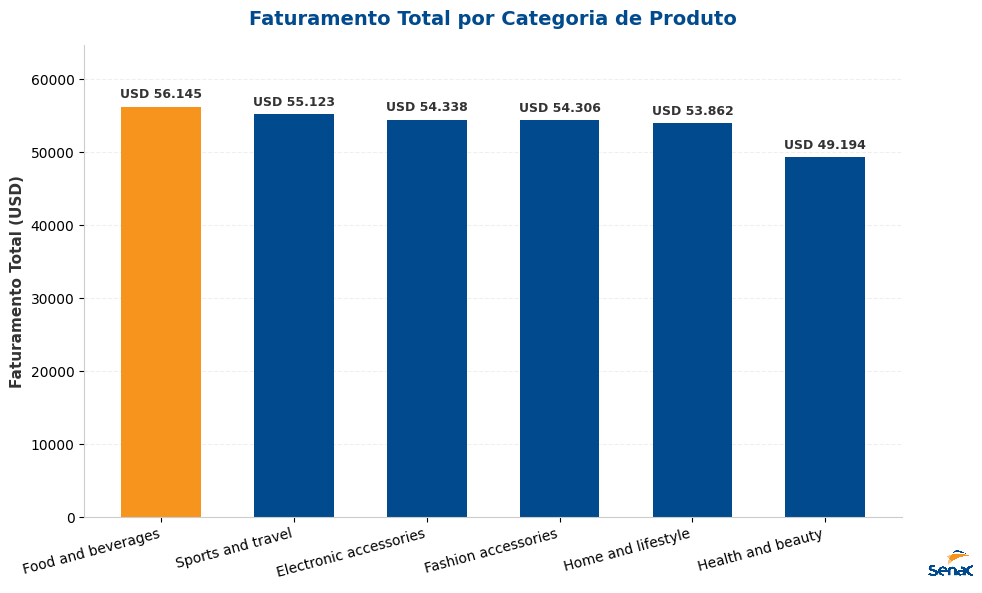

In [16]:
# ==========================
# 1. Faturamento por Categoria de Produto
# ==========================

faturamento_categoria = df.groupby('Product line')['Sales'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))

cores = [LARANJA_SENAC] + [AZUL_SENAC] * (len(faturamento_categoria) - 1)

bars = ax.bar(faturamento_categoria.index, faturamento_categoria.values, color=cores, width=0.6)

ax.set_title('Faturamento Total por Categoria de Produto', fontsize=14, pad=15, color=AZUL_SENAC, fontweight='bold')
ax.set_ylabel('Faturamento Total (USD)', fontsize=11, color='#333333', fontweight='bold')

plt.xticks(rotation=15, ha='right', fontsize=10)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + (max(faturamento_categoria.values) * 0.015),
        f'USD {height:,.0f}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        color='#333333'
    )

ax.set_ylim(0, max(faturamento_categoria.values) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.3, color='#cccccc')
ax.set_axisbelow(True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cccccc')
ax.spines['bottom'].set_color('#cccccc')

caminho_logo = 'logo_senac.png'

try:
    img_logo = Image.open(caminho_logo)
    imagebox = OffsetImage(img_logo, zoom=0.08)
    ab = AnnotationBbox(
        imagebox,
        (0.95, 0.05),
        xycoords='figure fraction',
        frameon=False
    )
    ax.add_artist(ab)
except FileNotFoundError:
    pass

plt.tight_layout()
plt.show()

**O que o gráfico mostra:**  
O faturamento total registrado em cada categoria de produto durante o período analisado.

**Qual decisão ele pode ajudar a tomar:**  
- Identificar as categorias que mais contribuem para o faturamento.
- Orientar análises de estoque, exposição e campanhas promocionais.
- Investigar possíveis causas para o menor faturamento de algumas categorias.
- Acompanhar mudanças no desempenho comercial das categorias.

**Por que essa informação é útil:**  
A comparação permite identificar quais categorias possuem maior participação nas vendas. Entretanto, faturamento elevado não significa necessariamente maior rentabilidade ou maior quantidade vendida.

**Principais resultados:**  
Food and beverages apresentou o maior faturamento, com aproximadamente USD 56,1 mil, seguido por Sports and travel, com USD 55,1 mil. Health and beauty apresentou o menor faturamento, com aproximadamente USD 49,2 mil.

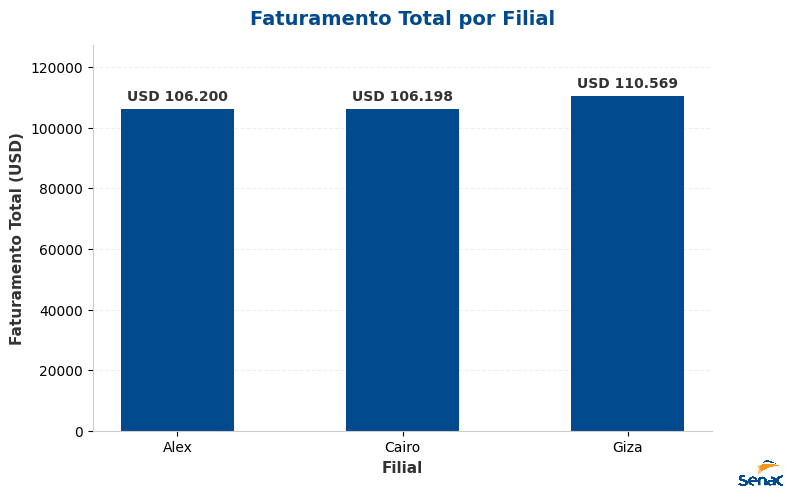

In [17]:
# ==========================
# 2. Faturamento por filial
# ==========================

faturamento_filial = df.groupby('Branch')['Sales'].sum()

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(faturamento_filial.index, faturamento_filial.values, color=AZUL_SENAC, width=0.5)

ax.set_title('Faturamento Total por Filial', fontsize=14, pad=15, color=AZUL_SENAC, fontweight='bold')
ax.set_xlabel('Filial', fontsize=11, color='#333333', fontweight='bold')
ax.set_ylabel('Faturamento Total (USD)', fontsize=11, color='#333333', fontweight='bold')

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + (max(faturamento_filial.values) * 0.015),
        f'USD {height:,.0f}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color='#333333'
    )

ax.set_ylim(0, max(faturamento_filial.values) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.3, color='#cccccc')
ax.set_axisbelow(True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cccccc')
ax.spines['bottom'].set_color('#cccccc')

caminho_logo = 'logo_senac.png'

try:
    img_logo = Image.open(caminho_logo)
    imagebox = OffsetImage(img_logo, zoom=0.08)
    ab = AnnotationBbox(
        imagebox,
        (0.95, 0.05),
        xycoords='figure fraction',
        frameon=False
    )
    ax.add_artist(ab)
except FileNotFoundError:
    pass

plt.tight_layout()
plt.show()

**O que o gráfico mostra:**  
O faturamento total registrado em cada filial durante o período analisado.

**Qual decisão ele pode ajudar a tomar:**  
- Comparar o desempenho comercial das unidades.
- Investigar fatores que podem explicar eventuais diferenças.
- Identificar práticas comerciais que possam ser compartilhadas entre as filiais.
- Apoiar a definição de metas específicas para cada unidade.

**Por que essa informação é útil:**  
A comparação ajuda a identificar diferenças de faturamento entre as filiais. Entretanto, o faturamento isolado não permite concluir se uma unidade é mais eficiente, pois não há informações sobre tamanho, custos, localização ou quantidade de funcionários.

**Principais resultados:**

Giza apresentou o maior faturamento, com aproximadamente USD 110,6 mil. Alex e Cairo registraram cerca de USD 106,2 mil cada, ficando praticamente empatadas. A diferença entre a maior e a menor filial foi de aproximadamente 4,1%.

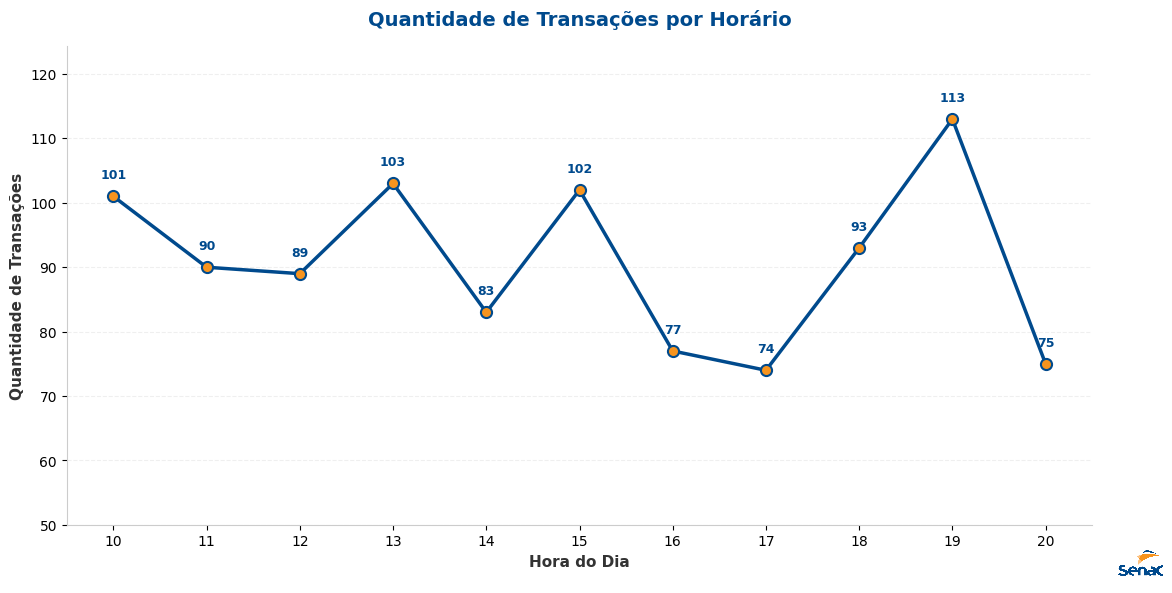

In [18]:
# ==========================
# 3. Quantidade de transações por horário
# ==========================

transacoes_horario = (
    df.groupby('Hour')['Invoice ID']
      .count()
      .sort_index()
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    transacoes_horario.index,
    transacoes_horario.values,
    color=AZUL_SENAC,
    linewidth=2.5,
    marker='o',
    markersize=8,
    markerfacecolor=LARANJA_SENAC,
    markeredgecolor=AZUL_SENAC,
    markeredgewidth=1.5
)

ax.set_title('Quantidade de Transações por Horário', fontsize=14, pad=15, color=AZUL_SENAC, fontweight='bold')
ax.set_xlabel('Hora do Dia', fontsize=11, color='#333333', fontweight='bold')
ax.set_ylabel('Quantidade de Transações', fontsize=11, color='#333333', fontweight='bold')
ax.set_xticks(transacoes_horario.index)

for x, y in zip(transacoes_horario.index, transacoes_horario.values):
    ax.text(
        x,
        y + (max(transacoes_horario.values) * 0.02),
        f'{int(y)}',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        color=AZUL_SENAC
    )

ax.set_ylim(50, max(transacoes_horario.values) * 1.1)
ax.grid(axis='y', linestyle='--', alpha=0.3, color='#cccccc')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cccccc')
ax.spines['bottom'].set_color('#cccccc')

caminho_logo = 'logo_senac.png'

try:
    img_logo = Image.open(caminho_logo)
    imagebox = OffsetImage(img_logo, zoom=0.08)
    ab = AnnotationBbox(
        imagebox,
        (0.95, 0.05),
        xycoords='figure fraction',
        frameon=False
    )
    ax.add_artist(ab)
except FileNotFoundError:
    pass

plt.tight_layout()
plt.show()

**O que o gráfico mostra:**  
A quantidade de transações realizadas em cada horário de funcionamento.

**Qual decisão ele pode ajudar a tomar:**  
- Identificar os horários com maior movimento de vendas.
- Ajustar a escala de funcionários conforme a demanda.
- Planejar reposição de produtos e intervalos da equipe.
- Desenvolver promoções para horários com menor movimento.

**Por que essa informação é útil:**  
A quantidade de transações funciona como um indicador do movimento operacional da loja e ajuda no planejamento da equipe.

**Principais resultados:**  
O maior movimento ocorreu às 19h, com 113 transações. O menor ocorreu às 17h, com 74 transações. Os horários de 10h, 13h e 15h também apresentaram mais de 100 transações.

> A quantidade de transações não representa necessariamente o número exato de clientes, pois uma mesma pessoa pode realizar mais de uma compra.

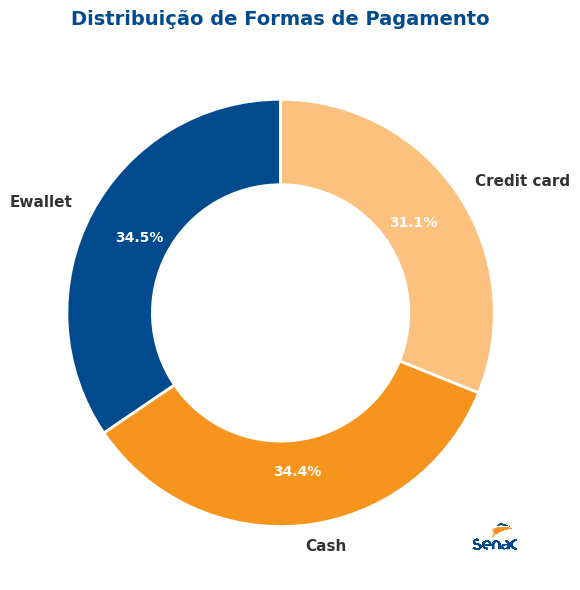

In [19]:
# ==========================
# 4. Formas de pagamento utilizadas
# ==========================

pagamento = df['Payment'].value_counts()

fig, ax = plt.subplots(figsize=(8, 6))

paleta_rosca = [AZUL_SENAC, LARANJA_SENAC, LARANJA_CLARO]

wedges, texts, autotexts = ax.pie(
    pagamento.values,
    labels=pagamento.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=paleta_rosca,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    pctdistance=0.75
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(10)

for text in texts:
    text.set_color('#333333')
    text.set_fontsize(11)
    text.set_fontweight('bold')

ax.set_title('Distribuição de Formas de Pagamento', fontsize=14, pad=15, color=AZUL_SENAC, fontweight='bold')

caminho_logo = 'logo_senac.png'

try:
    img_logo = Image.open(caminho_logo)
    imagebox = OffsetImage(img_logo, zoom=0.08)

    ab = AnnotationBbox(
        imagebox,
        (0.90, 0.08),
        xycoords='axes fraction',
        frameon=False
    )
    ax.add_artist(ab)
except Exception as e:
    print(f"Erro ao carregar a logo: {e}")

plt.tight_layout()
plt.show()

**O que o gráfico mostra:**  
A quantidade de transações realizadas por carteira digital, dinheiro e cartão de crédito.

**Qual decisão ele pode ajudar a tomar:**  
- Manter disponíveis diferentes formas de pagamento.
- Avaliar os custos e as condições de cada modalidade.
- Planejar promoções relacionadas aos meios de pagamento.
- Acompanhar possíveis mudanças no comportamento dos clientes.

**Por que essa informação é útil:**  
A análise permite conhecer a distribuição das transações entre os meios de pagamento e verificar se existe concentração em alguma modalidade.

**Principais resultados:**  
As formas de pagamento apresentaram distribuição relativamente equilibrada. A carteira digital foi utilizada em 345 transações, o dinheiro em 344 e o cartão de crédito em 311. Portanto, não foi identificada uma preferência dominante.

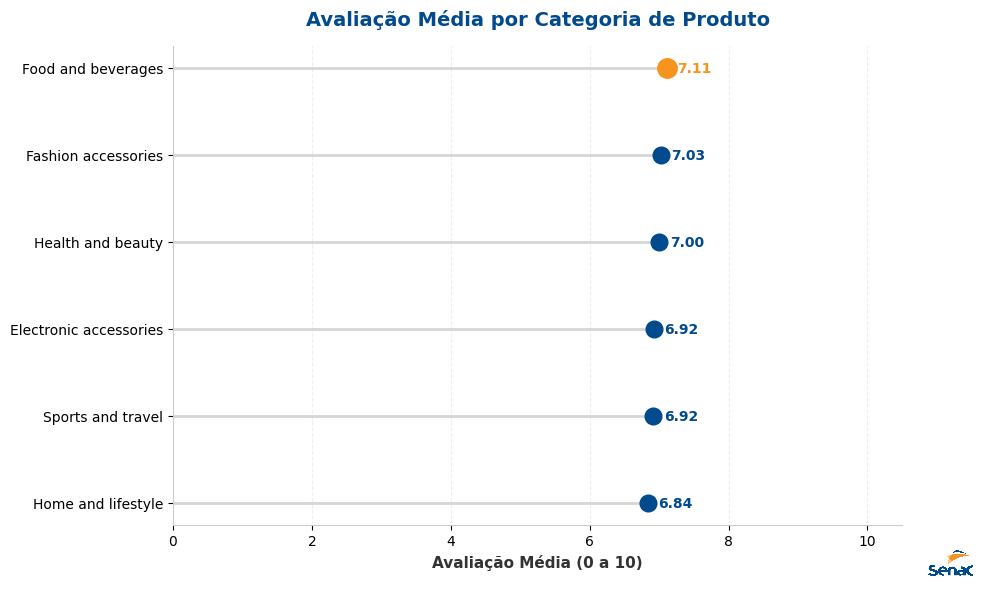

In [20]:
# ==========================
# 5. Avaliação média por categoria de produto
# ==========================

avaliacao_categoria = (
    df.groupby('Product line')['Rating']
      .mean()
      .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.hlines(
    y=avaliacao_categoria.index,
    xmin=0,
    xmax=avaliacao_categoria.values,
    color='#cccccc',
    alpha=0.8,
    linewidth=2
)

ax.plot(
    avaliacao_categoria.values,
    avaliacao_categoria.index,
    "o",
    markersize=12,
    color=AZUL_SENAC
)

maior_valor = avaliacao_categoria.max()
categoria_maior = avaliacao_categoria.idxmax()
ax.plot(
    maior_valor,
    categoria_maior,
    "o",
    markersize=14,
    color=LARANJA_SENAC
)

ax.set_title('Avaliação Média por Categoria de Produto', fontsize=14, pad=15, color=AZUL_SENAC, fontweight='bold')
ax.set_xlabel('Avaliação Média (0 a 10)', fontsize=11, color='#333333', fontweight='bold')

for i, (categoria, valor) in enumerate(zip(avaliacao_categoria.index, avaliacao_categoria.values)):
    ax.text(
        valor + 0.15,
        i,
        f'{valor:.2f}',
        va='center',
        fontsize=10,
        fontweight='bold',
        color=LARANJA_SENAC if valor == maior_valor else AZUL_SENAC
    )

ax.set_xlim(0, 10.5)
ax.grid(axis='x', linestyle='--', alpha=0.3, color='#cccccc')
ax.set_axisbelow(True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cccccc')
ax.spines['bottom'].set_color('#cccccc')

caminho_logo = 'logo_senac.png'

try:
    img_logo = Image.open(caminho_logo)
    imagebox = OffsetImage(img_logo, zoom=0.08)
    ab = AnnotationBbox(
        imagebox,
        (0.95, 0.05),
        xycoords='figure fraction',
        frameon=False
    )
    ax.add_artist(ab)
except FileNotFoundError:
    pass

plt.tight_layout()
plt.show()

**O que o gráfico mostra:**  
A avaliação média atribuída pelos clientes a cada categoria de produto.

**Qual decisão ele pode ajudar a tomar:**  
- Identificar categorias com avaliações inferiores às demais.
- Investigar possíveis problemas relacionados à qualidade, variedade, preço ou experiência de compra.
- Acompanhar a satisfação dos clientes após a realização de melhorias.

**Por que essa informação é útil:**  
A visualização acrescenta a perspectiva dos clientes à análise financeira. Entretanto, as diferenças entre as categorias são pequenas e, isoladamente, não comprovam a existência de problemas.

**Resultado observado:**  
A categoria *Food and beverages* apresentou a maior avaliação média, aproximadamente 7,11. Já *Home and lifestyle* apresentou a menor, aproximadamente 6,84. Como a diferença é de apenas 0,27 ponto, recomenda-se investigar outros períodos e informações antes de tomar uma decisão definitiva.

## 5. Implementação de Aprendizado de Máquina – Clusterização de Compras com K-Means

Esta etapa tem como objetivo aplicar um algoritmo de clusterização para identificar diferentes perfis de compras realizadas no supermercado, considerando a quantidade de produtos adquiridos e o valor total das transações.

In [21]:
# Importação das bibliotecas

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [22]:
# Preparação dos dados


# Selecionar as variáveis utilizadas no agrupamento
X = df[['Quantity', 'Sales']]

# Visualizar os dados selecionados
X.head()

,Quantity,Sales
0,7,548.9715
1,5,80.2200
2,7,340.5255
3,8,489.0480
4,7,634.3785


In [23]:
# Padronização dos dados


# Criar o padronizador
scaler = StandardScaler()

# Aplicar a padronização
X_scaled = scaler.fit_transform(X)

In [24]:
# Aplicação do K-Means


# Criar o modelo com 3 grupos
modelo = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Aplicar o modelo e identificar os grupos
df['Cluster'] = modelo.fit_predict(X_scaled)

# Visualizar os primeiros registros com os grupos identificados
df[['Quantity', 'Sales', 'Cluster']].head(10)

,Quantity,Sales,Cluster
0,7,548.9715,1
1,5,80.2200,0
2,7,340.5255,2
3,8,489.0480,2
4,7,634.3785,1
5,7,627.6165,1
6,6,433.6920,2
7,10,772.3800,1
8,2,76.1460,0
9,3,172.7460,0


In [25]:
# Análise dos grupos


# Calcular a quantidade de compras e as médias de cada grupo
resumo_clusters = df.groupby('Cluster').agg(
    Quantidade_Compras=('Invoice ID', 'count'),
    Media_Produtos=('Quantity', 'mean'),
    Media_Valor=('Sales', 'mean')
).round(2)

resumo_clusters

,Quantidade_Compras,Media_Produtos,Media_Valor
Cluster,,,
0,432,2.69,136.35
1,205,8.71,720.27
2,363,7.06,320.68


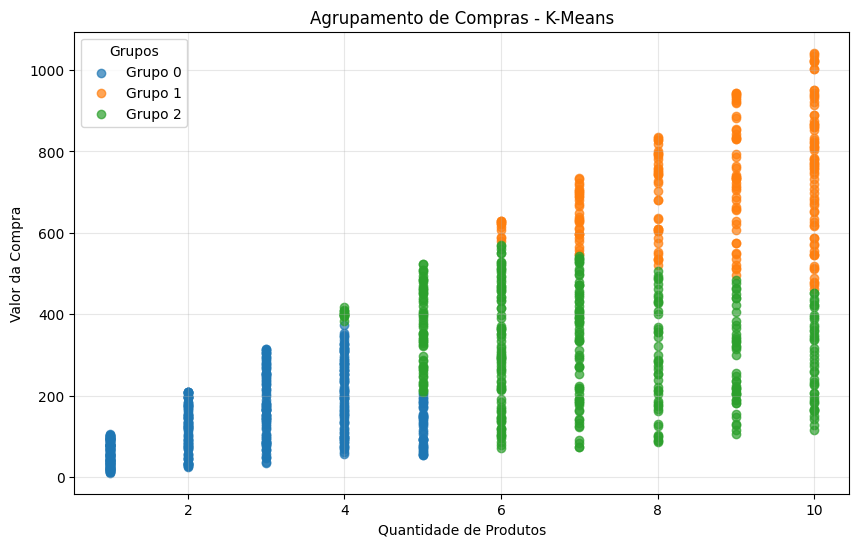

In [26]:
# Visualização dos agrupamentos


fig, ax = plt.subplots(figsize=(10, 6))

for grupo in sorted(df['Cluster'].unique()):

    dados = df[df['Cluster'] == grupo]

    ax.scatter(
        dados['Quantity'],
        dados['Sales'],
        label=f'Grupo {grupo}',
        alpha=0.7
    )

ax.set_title('Agrupamento de Compras - K-Means')
ax.set_xlabel('Quantidade de Produtos')
ax.set_ylabel('Valor da Compra')
ax.legend(title='Grupos')
ax.grid(alpha=0.3)

plt.show()

## Interpretação dos resultados

O algoritmo K-Means identificou três grupos de compras com características semelhantes, considerando a quantidade de produtos e o valor total das transações.

A análise da tabela e do gráfico permite observar diferenças entre os grupos, identificando padrões de compras com diferentes volumes e valores.

Essas informações podem auxiliar o supermercado a compreender melhor o comportamento das transações, apoiar análises comerciais e contribuir para o planejamento de ações promocionais.

## 6. Dashboard Interativo — Streamlit

Com o objetivo de facilitar a exploração e a interpretação dos resultados, foi desenvolvido um dashboard interativo utilizando o framework Streamlit, integrado às bibliotecas Pandas, Plotly e Scikit-learn.

A aplicação está implementada no arquivo `app.py` e permite visualizar indicadores de faturamento total, quantidade de transações, ticket médio e avaliação média dos clientes.

O painel também disponibiliza gráficos de faturamento por categoria e filial, quantidade de transações por horário, distribuição das formas de pagamento, avaliações médias por categoria e agrupamentos de transações identificados pelo algoritmo K-Means.

Para permitir análises direcionadas, foram implementados filtros por período, filial, categoria de produto e forma de pagamento. Os resultados exibidos são atualizados conforme as seleções do usuário.

Nesta implementação, o aplicativo utiliza diretamente o arquivo CSV original, enquanto a estrutura dimensional desenvolvida no MySQL permanece como um componente complementar do projeto.

O código-fonte do dashboard está disponível no arquivo `app.py`. Sua execução requer a instalação das dependências necessárias e o acesso ao conjunto de dados na estrutura de diretórios esperada pela aplicação.

In [ ]:
%pip install streamlit
!streamlit run app.py


     ---------------------------------------- 0.0/10.3 MB ? eta -:--:--
     - -------------------------------------- 0.5/10.3 MB 31.4 MB/s eta 0:00:01
     ------ --------------------------------- 1.7/10.3 MB 21.7 MB/s eta 0:00:01
     ---------- ----------------------------- 2.8/10.3 MB 22.5 MB/s eta 0:00:01
     --------------- ------------------------ 3.9/10.3 MB 22.6 MB/s eta 0:00:01
     -------------------- ------------------- 5.2/10.3 MB 25.5 MB/s eta 0:00:01
     ------------------------- -------------- 6.6/10.3 MB 24.7 MB/s eta 0:00:01
     ----------------------------- ---------- 7.7/10.3 MB 24.4 MB/s eta 0:00:01
     --------------------------------- ------ 8.7/10.3 MB 25.2 MB/s eta 0:00:01
     ------------------------------------- -- 9.7/10.3 MB 24.8 MB/s eta 0:00:01
     --------------------------------------  10.3/10.3 MB 24.2 MB/s eta 0:00:01
     --------------------------------------- 10.3/10.3 MB 21.8 MB/s eta 0:00:00
     ---------------------------------------- 0.


[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 7. Conclusão Geral

O desenvolvimento deste projeto permitiu aplicar técnicas de ciência de dados e inteligência de negócios na análise de transações comerciais de uma rede de supermercados. A partir de uma base contendo 1.000 registros, foram realizados procedimentos de carregamento, tratamento, verificação da consistência dos dados e análise exploratória, seguidos da construção de visualizações destinadas a apoiar a tomada de decisão.

As análises revelaram diferenças no faturamento entre categorias de produtos e filiais, variações na quantidade de transações ao longo do dia, uma distribuição relativamente equilibrada entre as formas de pagamento e pequenas diferenças nas avaliações médias dos clientes. Essas informações oferecem suporte para investigar oportunidades de melhoria nas operações, no atendimento e nas estratégias comerciais e administrativas, embora não sejam suficientes, isoladamente, para justificar mudanças definitivas.

Na segunda etapa do projeto, a aplicação do algoritmo K-Means ampliou a análise ao identificar três agrupamentos de transações, considerando a quantidade de produtos adquiridos e o valor total das compras. Os resultados permitiram reconhecer diferentes perfis de compra, demonstrando como o aprendizado de máquina pode complementar a análise descritiva e contribuir para a identificação de padrões comerciais.

Também foi desenvolvida uma estrutura dimensional no MySQL, organizada em uma tabela fato e tabelas de dimensão, com recursos de integridade, auditoria e consultas analíticas por meio de views. Essa estrutura oferece uma base para o armazenamento e a exploração das informações sob diferentes perspectivas gerenciais. Nesta versão, o notebook e o dashboard utilizam diretamente o conjunto de dados original, enquanto a implementação do banco de dados constitui um componente complementar, documentado separadamente.

Por fim, o dashboard interativo reuniu os principais indicadores e resultados em uma interface visual, facilitando a exploração e visualização das informações. O projeto demonstra o potencial da integração entre análise exploratória, modelagem de banco de dados, aprendizado de máquina e visualização para apoiar decisões mais fundamentadas. Como possibilidades de evolução, destacam-se a integração direta do dashboard ao banco de dados, a ampliação do período analisado e a incorporação de informações sobre estoque, custos operacionais e comportamento de compra ao longo do tempo.